# Zestaw 2: sieci konwolucyjne i ResNet

**Cel:** sprawdzić znajomość konwolucji, poolingu, budowy i uczenia sieci CNN, interpretacji wyników na CIFAR-10, operacji 1x1 i dilation oraz połączeń rezydualnych.

**Jak pracować?** W komórkach oznaczonych `TODO` uzupełnij `...` albo miejsca opisane komentarzem. Uruchamiaj komórki po kolei. Komórki `assert` są testami, więc mogą zgłaszać błąd, dopóki nie wykonasz zadania. Odpowiedzi opisowe wpisuj w komórkach Markdown.

In [59]:
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
import torch.nn.functional as F

torch.manual_seed(42)
np.random.seed(42)
print("PyTorch:", torch.__version__)
print("Uruchamiamy na CPU.")

PyTorch: 2.11.0+cu130
Uruchamiamy na CPU.


## 1. Konwolucja

Dla minibatcha o kształcie `(4, 3, 30, 30)` zastosuj konwolucję z **8 filtrami 3x3**, `stride=2` i `padding=1`. Uzupełnij kod, a następnie oblicz ręcznie wymiary wyjścia oraz liczbę parametrów warstwy, uwzględniając bias.

In [60]:
# TODO 1: zbuduj warstwę konwolucyjną i wykonaj forward.
x = torch.randn(4, 3, 30, 30)
conv = nn.Conv2d(3, 8, 3, stride=2, padding=1)
y_conv = conv(x)

# TODO: podaj liczbę uczonych parametrów warstwy.
liczba_parametrow = 8 * (3 * 3 * 3 + 1)
# 224 parametry
# H = W = (30 + 2 - 3) // 2 + 1 = 15

print("Wymiary:", x.shape, "->", y_conv.shape)
print("Liczba parametrów:", liczba_parametrow)

Wymiary: torch.Size([4, 3, 30, 30]) -> torch.Size([4, 8, 15, 15])
Liczba parametrów: 224


In [61]:
# Test 1: uruchom po wykonaniu TODO 1.
assert isinstance(conv, nn.Conv2d)
assert conv.in_channels == 3 and conv.out_channels == 8
assert conv.kernel_size == (3, 3) and conv.stride == (2, 2)
assert conv.padding == (1, 1) and conv.bias is not None
assert y_conv.shape == (4, 8, 15, 15)
assert liczba_parametrow == sum(p.numel() for p in conv.parameters()) == 224
print("Konwolucja: poprawne kształty i liczba parametrów")

Konwolucja: poprawne kształty i liczba parametrów


**Pytanie:** jak `stride` i `padding` wpływają na rozmiar map cech? Dlaczego pojedynczy filtr konwolucyjny musi uwzględniać wszystkie kanały wejściowe?

**Odpowiedź:** Im większy stride tym mniejszy rozmiar map cech, a padding dodaje obramowanie wokół obrazka i ogranicza zmniejszanie ich rozmiaru. Filtr konwolucyjny obejmuje wszystkie kanały, aby łączyć ich informacje w jedną mapę cech.

## 2. Pooling

Napisz max pooling 2x2 z krokiem 2 dla pojedynczego obrazu `(C, H, W)`. Możesz używać indeksowania, pętli i `.max()`, ale nie korzystaj z `nn.MaxPool2d` ani `F.max_pool2d` **wewnątrz własnej funkcji**. Załóż, że wysokość i szerokość są parzyste.

In [62]:
# TODO 2: uzupełnij własny max pooling.
def maxpool2x2(image):
    C, H, W = image.shape
    assert H % 2 == 0 and W % 2 == 0
    result = image.new_empty((C, H // 2, W // 2))

    # TODO: zapisz do result maksima z kolejnych okien 2x2.
    # Okno dla indeksu (c, i, j) zaczyna się w (2*i, 2*j).
    for c in range(C):
        for i in range(H // 2):
            for j in range(W // 2):
                window = image[c, 2*i:2*i+2, 2*j:2*j+2]
                result[c, i, j] = window.max()

    return result

In [63]:
# Test 2: uruchom po wykonaniu TODO 2.
example = torch.tensor([[[-5., -1., -2., -9.],
                         [-3., -4., -7., -8.],
                         [ 0., -6., -2., -3.],
                         [-10., -11., -12., -1.]]])
for image in [example, torch.randn(3, 8, 6) - 4, torch.randn(2, 4, 4)]:
    actual = maxpool2x2(image)
    expected = F.max_pool2d(image.unsqueeze(0), 2, stride=2).squeeze(0)
    torch.testing.assert_close(actual, expected)
print("Max pooling: wyniki zgodne z PyTorch")

Max pooling: wyniki zgodne z PyTorch


**Pytanie:** dlaczego max pooling nie ma parametrów uczonych podczas treningu? Co zmienia się w tensorze po zastosowaniu poolingu 2x2 ze `stride=2`?

**Odpowiedź:** Max pooling nie ma uczonych wag ani biasów, bo wybiera maksimum według ustalonej reguły. Pooling 2×2 ze stride=2 zmienia (C, H, W) na (C, H/2, W/2).

## 3. Własna sieć CNN

Zbuduj model do klasyfikacji obrazów RGB na 4 klasy. Użyj kolejno `Conv2d(3, 8, 3, padding=1)`, `ReLU`, `MaxPool2d(2)`, `Conv2d(8, 16, 3, padding=1)`, `ReLU`, `AdaptiveAvgPool2d(1)`, `Flatten` i `Linear(16, 4)`. Model ma przyjmować obrazy o różnych wysokościach i szerokościach.

In [64]:
# TODO 3: uzupełnij moduły i metodę forward.
class TinyCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            # TODO: dwie konwolucje, aktywacje, max pooling i GAP.
            nn.Conv2d(3, 8, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(8, 16, 3, padding=1),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d(1)
        )
        self.classifier = nn.Sequential(
            # TODO: Flatten i Linear zwracający 4 logity.
            nn.Flatten(),
            nn.Linear(16, 4)
        )

    def forward(self, x):
        return self.classifier(self.features(x))


model = TinyCNN()
logits = model(torch.randn(5, 3, 32, 32))
print("Wymiary logitów:", logits.shape)
print("Liczba parametrów:", sum(p.numel() for p in model.parameters()))

Wymiary logitów: torch.Size([5, 4])
Liczba parametrów: 1460


In [65]:
# Test 3: uruchom po wykonaniu TODO 3.
assert logits.shape == (5, 4)
assert model(torch.randn(2, 3, 20, 28)).shape == (2, 4)
assert sum(isinstance(layer, nn.Conv2d) for layer in model.modules()) == 2
assert any(isinstance(layer, nn.MaxPool2d) for layer in model.modules())
assert any(isinstance(layer, nn.AdaptiveAvgPool2d) for layer in model.modules())
assert sum(p.numel() for p in model.parameters()) == 1460
print("CNN: poprawna architektura, wymiary i liczba parametrów")

CNN: poprawna architektura, wymiary i liczba parametrów


**Pytanie:** co daje zastosowanie `AdaptiveAvgPool2d(1)` przed klasyfikatorem? Dlaczego nie wstawiamy `softmax` na końcu modelu trenowanego z `CrossEntropyLoss`?

**Odpowiedź:** AdaptiveAvgPool2d(1) robi jedną wartość na kanał, żeby klasyfikator obsługiwał różne rozmiary obrazów. Nie dodajemy softmax, ponieważ CrossEntropyLoss przyjmuje logity i posiada w sobie softmax.

## 4. Funkcja straty i trening

Wykonaj jeden krok uczenia na gotowym minibatchu. Użyj `F.cross_entropy` bez wcześniejszego `softmax` i zwróć stratę jako zwykłą liczbę typu `float`.

In [66]:
# Dane do zadania: nie wymagają pobierania zewnętrznego zbioru.
torch.manual_seed(7)
x_batch = torch.randn(8, 3, 16, 16)
y_batch = torch.tensor([0, 1, 2, 3, 1, 0, 3, 2])
train_model = TinyCNN()
optimizer = torch.optim.SGD(train_model.parameters(), lr=0.05)


# TODO 4: uzupełnij jeden krok treningu.
def train_step(model, x, y, optimizer):
    model.train()
    # TODO: zero_grad -> forward -> loss -> backward -> step
    optimizer.zero_grad(set_to_none=True)
    logits = model(x)
    loss = F.cross_entropy(logits, y)
    loss.backward()
    optimizer.step()
    return loss.item()

In [67]:
# Test 4: uruchom po wykonaniu TODO 4.
weights_before = [p.detach().clone() for p in train_model.parameters()]
loss_value = train_step(train_model, x_batch, y_batch, optimizer)
assert isinstance(loss_value, float) and np.isfinite(loss_value) and loss_value > 0
assert any(not torch.equal(a, p) for a, p in zip(weights_before, train_model.parameters()))
assert any(p.grad is not None for p in train_model.parameters())
print("Krok treningu: strata i aktualizacja wag poprawne")

Krok treningu: strata i aktualizacja wag poprawne


## 5. CIFAR-10 i diagnoza jakości

Poniższe metryki pochodzą z przykładowego eksperymentu na obrazach CIFAR-10. Dla kolejnych epok zapisano `train accuracy` i `validation accuracy`. Wybierz najlepszą epokę **na podstawie walidacji** i oblicz różnicę między końcowym `train accuracy` a `validation accuracy`.

In [68]:
train_acc = np.array([0.45, 0.61, 0.75, 0.84, 0.91, 0.96])
val_acc = np.array([0.43, 0.56, 0.67, 0.70, 0.68, 0.64])

# TODO 5: numer epoki licz od 1, a różnicę zapisz jako ułamek (np. 0.20).
najlepsza_epoka = int(np.argmax(val_acc)) + 1
roznica_koncowa = float(train_acc[-1] - val_acc[-1])

assert najlepsza_epoka == 4
assert np.isclose(roznica_koncowa, 0.32)
print("Najlepsza epoka:", najlepsza_epoka)
print("Końcowa różnica accuracy:", f"{roznica_koncowa:.0%}")

Najlepsza epoka: 4
Końcowa różnica accuracy: 32%


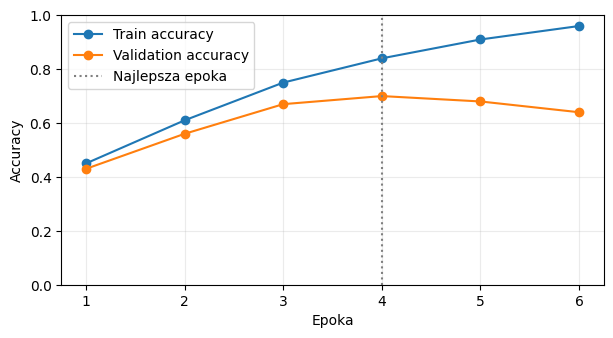

In [69]:
# Wizualizacja gotowa, uruchom po uzupełnieniu TODO 5.
epoki = np.arange(1, len(train_acc) + 1)
plt.figure(figsize=(7, 3.5))
plt.plot(epoki, train_acc, marker="o", label="Train accuracy")
plt.plot(epoki, val_acc, marker="o", label="Validation accuracy")
plt.axvline(najlepsza_epoka, linestyle=":", color="gray", label="Najlepsza epoka")
plt.xlabel("Epoka")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.grid(alpha=0.25)
plt.legend()
plt.show()

**Do omówienia:** co sugeruje rosnąca różnica między wynikami treningowymi i walidacyjnymi? Podaj dwie metody ograniczenia tego problemu. Dlaczego zbiór testowy należy zachować na końcową ocenę modelu?

- Rosnąca różnica sugeruje przeuczenie.
- Przeuczenie można ograniczyć przez early stopping i augmentację danych treningowych.
- Zbiór testowy pozostawiamy do końcowej oceny, aby model się na nim nie uczył, żeby model się do niego nie dopasował.

## 6. Konwolucja 1x1, dilation i GAP

Zbuduj przepływ przez trzy przygotowane warstwy. `pointwise` zmienia liczbę kanałów, `dilated` wykorzystuje powiększone pole recepcyjne, a `gap` uśrednia każdą mapę cech do pojedynczej wartości. Funkcja powinna zwrócić wektor cech dla każdego elementu minibatcha.

In [70]:
pointwise = nn.Conv2d(16, 24, kernel_size=1, bias=False)
dilated = nn.Conv2d(24, 24, kernel_size=3, padding=2, dilation=2, bias=False)
gap = nn.AdaptiveAvgPool2d(1)


# TODO 6: zastosuj pointwise -> dilated -> gap -> spłaszczenie.
def feature_vector(x):
    x = pointwise(x)
    x = dilated(x)
    x = gap(x)
    return x.flatten(start_dim=1)
# Kolejne kształty: (B,16,H,W) -> (B,24,H,W) -> (B,24,H,W) -> (B,24,1,1) -> (B,24).

features = torch.randn(2, 16, 20, 20)
vectors = feature_vector(features)
print("Wymiary wektora cech:", vectors.shape)

Wymiary wektora cech: torch.Size([2, 24])


In [71]:
# Test 6: uruchom po wykonaniu TODO 6.
reference = gap(dilated(pointwise(features))).flatten(start_dim=1)
assert vectors.shape == (2, 24)
torch.testing.assert_close(vectors, reference)
print("Operacje 1x1, dilation i GAP: poprawny wynik")

Operacje 1x1, dilation i GAP: poprawny wynik


## 7. Blok rezydualny ResNet

Uzupełnij blok obliczający `ReLU(F(x) + shortcut(x))`. Gałąź główna jest gotowa. Jeśli liczba kanałów i rozdzielczość wejścia nie zmieniają się, użyj `nn.Identity()`. W przeciwnym przypadku użyj projekcji `Conv2d` 1x1 z odpowiednim `stride` oraz `BatchNorm2d`.

In [72]:
# TODO 7: zbuduj shortcut i uzupełnij forward.
class BasicResidualBlock(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()
        self.main = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, stride=stride, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(),
            nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
        )
        # TODO: Identity albo Conv2d 1x1 + BatchNorm2d.
        if in_channels == out_channels and stride == 1:
          self.shortcut = nn.Identity()
        else:
          self.shortcut = nn.Sequential(
              nn.Conv2d(in_channels, out_channels, 1, stride=stride, bias=False),
              nn.BatchNorm2d(out_channels),
          )
        self.activation = nn.ReLU()

    def forward(self, x):
        # TODO: dodaj wynik głównej gałęzi do shortcut i zastosuj ReLU.
        return self.activation(self.main(x) + self.shortcut(x))

In [73]:
# Test 7: uruchom po wykonaniu TODO 7.
block_same = BasicResidualBlock(8, 8, stride=1)
block_down = BasicResidualBlock(8, 16, stride=2)
assert isinstance(block_same.shortcut, nn.Identity)
assert isinstance(block_down.shortcut, nn.Sequential)
assert isinstance(block_down.shortcut[0], nn.Conv2d)
assert block_down.shortcut[0].kernel_size == (1, 1)
assert block_down.shortcut[0].stride == (2, 2)
assert isinstance(block_down.shortcut[1], nn.BatchNorm2d)
assert block_same(torch.randn(2, 8, 16, 16)).shape == (2, 8, 16, 16)
assert block_down(torch.randn(2, 8, 16, 16)).shape == (2, 16, 8, 8)
print("ResNet: poprawny shortcut i kształty tensorów")

ResNet: poprawny shortcut i kształty tensorów


## 8. Wnioski

Zapisz **krótkie odpowiedzi**, odwołując się do zadań:

1. Czym różnią się `model.eval()` i `torch.no_grad()`? Dlaczego oba często pojawiają się podczas walidacji?
2. Jak interpretujesz wykres dla CIFAR-10? Jakie dwie zmiany w treningu można zaproponować i dlaczego nie dobieramy ich na zbiorze testowym?
3. Dlaczego w ResNet potrzebny jest `shortcut`, a kiedy musi zawierać projekcję 1x1? Jakie efektywne pole recepcyjne ma filtr 3x3 z `dilation=2`?

Ad 1. model.eval() zmienia zachowanie dropout i BatchNorm, a torch.no_grad() wyłącza liczenie gradientów. Podczas walidacji stosujemy oba, aby uzyskać zachowanie ewaluacyjne i oszczędzić pamięć.

Ad 2. Po epoce 4 wynik treningowy rośnie, a walidacyjny spada, czyli mamy przeuczenie. Może pomóc early stopping i augmentacja treningowa. Zmiany dobieramy na walidacji, bo test musi być zawsze niezależną oceną końcową.

Ad 3. Shortcut powoduje przepływ informacji i gradientów, a projekcja 1×1 dopasowuje kształty przy zmianie liczby kanałów. Filtr 3×3 z dilation=2 ma efektywny zasięg 5×5.